# Stage 2.1 — LangChain Agentic Trade Signal Forecaster

Multi-agent system that wraps the Stage 2 alpha models in a reasoning layer:

| Agent | Role |
|-------|------|
| **QuantAnalyst** | Reads signal features + model predictions, scores signal quality |
| **RiskScout** | Detects market regime, flags high-volatility / drawdown risk |
| **EnsembleOrchestrator** | Synthesises all agent outputs → ranked buy/sell signals |

**Reads from Stage 2:** `alpha_mu.parquet`, `master_dataset.parquet`, `stage2_primary.json`

## 0. Install dependencies

In [46]:
import subprocess, sys, os as _os, glob as _glob

def _pip(*pkgs):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--no-user', '-q', *pkgs])

# jiter arch-safety: remove any x86_64 build from ~/.local that shadows this arm64 env
_bad = _glob.glob(_os.path.expanduser('~/.local/lib/python*/site-packages/jiter*'))
for _p in _bad:
    import shutil as _sh
    _sh.rmtree(_p) if _os.path.isdir(_p) else _os.remove(_p)
    print(f'Removed stale x86_64 package: {_p}')

# langchain-google-genai  (free Gemini API — get key at aistudio.google.com)
try:
    import langchain_google_genai
    print('langchain-google-genai already installed')
except ImportError:
    print('Installing langchain-google-genai...')
    _pip('langchain-google-genai')
    print('Done')

try:
    import langgraph
    print('langgraph already installed')
except ImportError:
    print('Installing langgraph...')
    _pip('langgraph')
    print('Done')

langchain-google-genai already installed
langgraph already installed


## 1. Imports & Config

In [47]:
import os, json, warnings, time
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from IPython.display import display, Markdown
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# ── Workspace paths (mirror Stage 2) ──────────────────────────────────────────
WORKSPACE  = "/Applications/Projects/Hackathons/quantum_ai/workspace"
DATA_DIR   = os.path.join(WORKSPACE, "data")
MODELS_DIR = os.path.join(WORKSPACE, "models")

TRAIN_END  = "2017-12-31"
TEST_START = "2018-01-01"
TARGET     = "fwd_return_5d"

# ── Google AI Studio (free tier) ──────────────────────────────────────────────
# Project: gen-lang-client-0937965073
# Get your free API key at: https://aistudio.google.com/app/apikey
GOOGLE_API_KEY       = os.environ.get("GOOGLE_API_KEY", "")
GOOGLE_CLOUD_PROJECT = "gen-lang-client-0937965073"
os.environ["GOOGLE_CLOUD_PROJECT"] = GOOGLE_CLOUD_PROJECT

# Preferred model order — first one available to your key wins (resolved below)
MODEL_PREFERENCE = [
    "gemini-2.5-flash",
    "gemini-2.5-flash-lite",
    "gemini-flash-latest",
    "gemini-2.0-flash-lite",
    "gemini-2.0-flash",
]
LLM_TEMPERATURE = 0.0

print(f"Workspace   : {WORKSPACE}")
print(f"GCP project : {GOOGLE_CLOUD_PROJECT}")
print(f"API key     : {'SET' if GOOGLE_API_KEY else 'NOT SET'}")


Workspace   : /Applications/Projects/Hackathons/quantum_ai/workspace
GCP project : gen-lang-client-0937965073
API key     : SET


## 2. Load Stage 2 artifacts

In [48]:
# ── Master dataset ─────────────────────────────────────────────────────────────
master = pd.read_parquet(os.path.join(DATA_DIR, 'master_dataset.parquet'))
master['timestamp'] = pd.to_datetime(master['timestamp'])
master = master.set_index(['timestamp', 'ticker'])

EXCLUDE = {
    'sector', 'price', 'high', 'low', 'volume',
    'return_1d', 'fwd_return_1d', 'fwd_return_5d',
    'regime', 'news_today', 'news_yesterday',
    'market_news_today', 'market_news_yesterday',
    'n_news_today', 'n_market_news_today',
    'news_sent_today', 'news_sent_yesterday',
}
SIGNAL_COLS = [c for c in master.columns if c not in EXCLUDE]
TICKERS     = master.index.get_level_values('ticker').unique().tolist()

print(f'Master     : {master.shape}  |  {len(TICKERS)} tickers  |  {len(SIGNAL_COLS)} signals')
print(f'Date range : {master.index.get_level_values("timestamp").min().date()} '
      f'→ {master.index.get_level_values("timestamp").max().date()}')

# ── Alpha model predictions from Stage 2 ──────────────────────────────────────
alpha_mu = pd.read_parquet(os.path.join(DATA_DIR, 'alpha_mu.parquet'))
print(f'\nalpha_mu   : {alpha_mu.shape}')
print(f'Columns    : {list(alpha_mu.columns)}')

# ── Stage 2 primary model metadata ────────────────────────────────────────────
with open(os.path.join(DATA_DIR, 'stage2_primary.json')) as f:
    stage2_meta = json.load(f)

PRIMARY_MODEL = stage2_meta['primary_model']
print(f'\nPrimary model : {PRIMARY_MODEL}  (IC={stage2_meta["IC"]:.4f})')

# ── Test-set slices ────────────────────────────────────────────────────────────
ts = master.index.get_level_values('timestamp')
test_mask = ts >= pd.Timestamp(TEST_START)
master_test = master[test_mask].copy()
TEST_DATES  = sorted(master_test.index.get_level_values('timestamp').unique())
print(f'\nTest dates : {len(TEST_DATES)}  ({TEST_DATES[0].date()} → {TEST_DATES[-1].date()})')

Master     : (37460, 45)  |  20 tickers  |  28 signals
Date range : 2013-01-02 → 2020-06-10

alpha_mu   : (12180, 7)
Columns    : ['lightgbm', 'chronos', 'vqc', 'xpyq', 'timesfm', 'kronos', 'primary']

Primary model : LightGBM  (IC=0.0841)

Test dates : 614  (2018-01-02 → 2020-06-10)


## 3. Helper utilities

In [49]:
def spearman_ic(pred: pd.Series, actual: pd.Series) -> float:
    d = pd.concat([pred, actual], axis=1).dropna()
    if len(d) < 10:
        return float('nan')
    return float(spearmanr(d.iloc[:, 0], d.iloc[:, 1])[0])


def long_short_sharpe(pred: pd.Series, actual: pd.Series, top_n: int = 5) -> float:
    d = pd.concat([pred.rename('p'), actual.rename('y')], axis=1).dropna().reset_index()
    daily = []
    for _, g in d.groupby('timestamp'):
        if len(g) < 2 * top_n:
            continue
        g = g.sort_values('p')
        daily.append(g.tail(top_n)['y'].mean() - g.head(top_n)['y'].mean())
    if not daily:
        return float('nan')
    r = pd.Series(daily)
    return float(r.mean() / (r.std() + 1e-9) * np.sqrt(252 / 5))


def nearest_date(target_date: str) -> pd.Timestamp:
    """Return the nearest available test date."""
    ts = pd.Timestamp(target_date)
    idx = np.searchsorted(TEST_DATES, ts)
    idx = min(idx, len(TEST_DATES) - 1)
    return TEST_DATES[idx]


def detect_regime(date: pd.Timestamp, lookback: int = 20) -> dict:
    """Simple rolling-return-based regime: bull / bear / neutral."""
    pos = TEST_DATES.index(date) if date in TEST_DATES else -1
    if pos < lookback:
        return {'regime': 'unknown', 'avg_return': float('nan'), 'volatility': float('nan')}
    window_dates = TEST_DATES[pos - lookback: pos]
    returns = master_test.loc[master_test.index.get_level_values('timestamp').isin(window_dates), TARGET].dropna()
    avg_ret = float(returns.mean())
    vol     = float(returns.std())
    if avg_ret > 0.002:
        regime = 'bull'
    elif avg_ret < -0.002:
        regime = 'bear'
    else:
        regime = 'neutral'
    return {'regime': regime, 'avg_return': round(avg_ret, 6), 'volatility': round(vol, 6)}


print('Helpers ready: spearman_ic, long_short_sharpe, nearest_date, detect_regime')

Helpers ready: spearman_ic, long_short_sharpe, nearest_date, detect_regime


## 4. LangChain Tool Definitions

Each tool wraps a deterministic analytical function so the agent can call it with structured arguments.

In [50]:
from langchain_core.tools import tool
from typing import Optional

# Actual columns in alpha_mu: lightgbm, chronos, vqc, xpyq, timesfm, kronos, primary
ALPHA_COLS = [c for c in ['lightgbm', 'xpyq', 'vqc', 'chronos', 'timesfm', 'kronos']
              if c in alpha_mu.columns]
print(f'Alpha model columns available: {ALPHA_COLS}')


# ── Tool 1: fetch model predictions for a date ─────────────────────────────────
@tool
def fetch_predictions(date: str, top_n: int = 10) -> str:
    """Fetch alpha model predictions for all tickers on a given date.
    Returns the top-N long and short picks ranked by the primary model signal.
    date format: YYYY-MM-DD"""
    ts = nearest_date(date)
    try:
        preds = alpha_mu.xs(ts, level='timestamp')
    except KeyError:
        return f'No predictions available for date {date} (nearest: {ts.date()})'

    preds = preds.sort_values('primary', ascending=False)
    show_cols = ['primary'] + ALPHA_COLS[:3]
    top_long  = preds.head(top_n)[show_cols].round(5)
    top_short = preds.tail(top_n)[show_cols].round(5)

    return (
        f'Date: {ts.date()} | Primary model: {PRIMARY_MODEL}\n\n'
        f'TOP {top_n} LONG candidates:\n{top_long.to_string()}\n\n'
        f'TOP {top_n} SHORT candidates:\n{top_short.to_string()}'
    )


# ── Tool 2: signal feature snapshot for a ticker ───────────────────────────────
@tool
def get_signal_features(ticker: str, date: str) -> str:
    """Return the raw quantitative signal features for a specific ticker on a date.
    Signals include momentum, mean-reversion, volatility, and factor exposure metrics.
    date format: YYYY-MM-DD"""
    ts = nearest_date(date)
    ticker = ticker.upper()
    try:
        row = master_test.loc[(ts, ticker), SIGNAL_COLS]
    except KeyError:
        return f'No data for ticker={ticker} on {date} (nearest {ts.date()})'

    vals = row.dropna().sort_values(ascending=False)
    top5 = vals.head(5).round(4).to_dict()
    bot5 = vals.tail(5).round(4).to_dict()
    return (
        f'Ticker: {ticker} | Date: {ts.date()}\n'
        f'Strongest bullish signals: {top5}\n'
        f'Strongest bearish signals: {bot5}\n'
        f'Non-null features: {len(vals)}/{len(SIGNAL_COLS)}'
    )


# ── Tool 3: market regime ──────────────────────────────────────────────────────
@tool
def get_market_regime(date: str) -> str:
    """Classify the current market regime (bull / bear / neutral) based on
    rolling 20-day cross-sectional average returns and volatility.
    date format: YYYY-MM-DD"""
    ts = nearest_date(date)
    regime_info = detect_regime(ts)
    return (
        f'Date: {ts.date()}\n'
        f'Regime    : {regime_info["regime"].upper()}\n'
        f'Avg return: {regime_info["avg_return"]}\n'
        f'Volatility: {regime_info["volatility"]}'
    )


# ── Tool 4: model IC report ────────────────────────────────────────────────────
@tool
def get_model_ic_report() -> str:
    """Compute and return Information Coefficient (IC) for every alpha model
    in alpha_mu over the full test period. IC measures rank correlation
    between predicted and actual 5-day forward returns."""
    y_test = master_test[TARGET].dropna()
    report_lines = [f'Model IC report (test: {TEST_START} → {TEST_DATES[-1].date()})']
    report_lines.append('-' * 45)
    for col in alpha_mu.columns:
        pred = alpha_mu[col].reindex(y_test.index)
        ic   = spearman_ic(pred, y_test)
        sh   = long_short_sharpe(pred, y_test)
        report_lines.append(f'{col:20s}: IC={ic:+.4f}  Sharpe={sh:+.3f}')
    return '\n'.join(report_lines)


# ── Tool 5: ensemble signal with custom weights ────────────────────────────────
@tool
def compute_ensemble_signal(date: str, lgb_w: float = 0.4, xpyq_w: float = 0.3,
                             vqc_w: float = 0.2, chronos_w: float = 0.1,
                             top_n: int = 10) -> str:
    """Build a weighted ensemble forecast signal from the individual alpha models
    (lightgbm, xpyq, vqc, chronos) and return ranked ticker recommendations.
    Weights are auto-normalised so they don't need to sum to 1.
    date format: YYYY-MM-DD"""
    ts = nearest_date(date)
    try:
        preds = alpha_mu.xs(ts, level='timestamp').copy()
    except KeyError:
        return f'No data for {date}'

    total = lgb_w + xpyq_w + vqc_w + chronos_w + 1e-9
    lgb_w /= total; xpyq_w /= total; vqc_w /= total; chronos_w /= total

    preds['ensemble'] = (
        lgb_w     * preds.get('lightgbm', pd.Series(0, index=preds.index)).fillna(0) +
        xpyq_w    * preds.get('xpyq',     pd.Series(0, index=preds.index)).fillna(0) +
        vqc_w     * preds.get('vqc',      pd.Series(0, index=preds.index)).fillna(0) +
        chronos_w * preds.get('chronos',  pd.Series(0, index=preds.index)).fillna(0)
    )
    preds = preds.sort_values('ensemble', ascending=False)
    show  = ['ensemble'] + ALPHA_COLS[:3]
    longs  = preds.head(top_n)[show].round(5)
    shorts = preds.tail(top_n)[show].round(5)
    return (
        f'Ensemble | Date: {ts.date()} | '
        f'Weights: LGB={lgb_w:.2f} XPYQ={xpyq_w:.2f} VQC={vqc_w:.2f} CHR={chronos_w:.2f}\n\n'
        f'LONG  (top {top_n}):\n{longs.to_string()}\n\n'
        f'SHORT (top {top_n}):\n{shorts.to_string()}'
    )


# ── Tool 6: rolling IC over a date window ─────────────────────────────────────
@tool
def rolling_ic_window(start_date: str, end_date: str, model: str = 'primary') -> str:
    """Compute the rolling Spearman IC for a specific model column in alpha_mu
    over a user-specified date window. Useful for detecting model decay.
    model must be one of: primary, lightgbm, xpyq, vqc, chronos, timesfm, kronos
    date format: YYYY-MM-DD"""
    if model not in alpha_mu.columns:
        return f'Unknown model "{model}". Available: {list(alpha_mu.columns)}'
    ts_start = nearest_date(start_date)
    ts_end   = nearest_date(end_date)
    y_test   = master_test[TARGET].dropna()
    dates_in_window = [d for d in TEST_DATES if ts_start <= d <= ts_end]
    if not dates_in_window:
        return f'No test dates in range {start_date} → {end_date}'

    ics = []
    for d in dates_in_window:
        try:
            pred   = alpha_mu.xs(d, level='timestamp')[model]
            actual = y_test.xs(d, level='timestamp') if d in y_test.index.get_level_values('timestamp') else pd.Series(dtype=float)
            ics.append({'date': d.date(), 'ic': spearman_ic(pred, actual)})
        except Exception:
            continue

    ic_df = pd.DataFrame(ics).dropna()
    if ic_df.empty:
        return 'Insufficient data for IC calculation'
    return (
        f'Rolling IC for "{model}" | {ts_start.date()} → {ts_end.date()}\n'
        f'Mean IC    : {ic_df["ic"].mean():+.4f}\n'
        f'Std  IC    : {ic_df["ic"].std():.4f}\n'
        f'Min  IC    : {ic_df["ic"].min():+.4f}\n'
        f'Max  IC    : {ic_df["ic"].max():+.4f}\n'
        f'% positive : {(ic_df["ic"] > 0).mean():.1%}\n'
        f'Sample (last 5):\n{ic_df.tail(5).to_string(index=False)}'
    )


TOOLS = [fetch_predictions, get_signal_features, get_market_regime,
         get_model_ic_report, compute_ensemble_signal, rolling_ic_window]

print(f'Registered {len(TOOLS)} tools:')
for t in TOOLS:
    print(f'  • {t.name}')

Alpha model columns available: ['lightgbm', 'xpyq', 'vqc', 'chronos', 'timesfm', 'kronos']
Registered 6 tools:
  • fetch_predictions
  • get_signal_features
  • get_market_regime
  • get_model_ic_report
  • compute_ensemble_signal
  • rolling_ic_window


## 5. LLM Setup (Google Gemini via langchain-google-genai)

In [51]:
# Optional: list all Gemini models available for your key
# Run this if you get a 404 to pick a valid model name
import google.genai as genai_sdk

_client = genai_sdk.Client(api_key=GOOGLE_API_KEY)
_available = [
    m.name for m in _client.models.list()
    if 'generateContent' in (m.supported_actions or [])
    and 'gemini' in m.name.lower()
]
print('Available Gemini models for your key:')
for m in sorted(_available):
    print(' ', m)

Available Gemini models for your key:
  models/gemini-2.0-flash
  models/gemini-2.0-flash-001
  models/gemini-2.0-flash-lite
  models/gemini-2.0-flash-lite-001
  models/gemini-2.5-computer-use-preview-10-2025
  models/gemini-2.5-flash
  models/gemini-2.5-flash-image
  models/gemini-2.5-flash-lite
  models/gemini-2.5-flash-preview-tts
  models/gemini-2.5-pro
  models/gemini-2.5-pro-preview-tts
  models/gemini-3-flash-preview
  models/gemini-3-pro-image
  models/gemini-3-pro-image-preview
  models/gemini-3-pro-preview
  models/gemini-3.1-flash-image
  models/gemini-3.1-flash-image-preview
  models/gemini-3.1-flash-lite
  models/gemini-3.1-flash-lite-preview
  models/gemini-3.1-flash-tts-preview
  models/gemini-3.1-pro-preview
  models/gemini-3.1-pro-preview-customtools
  models/gemini-3.5-flash
  models/gemini-flash-latest
  models/gemini-flash-lite-latest
  models/gemini-pro-latest
  models/gemini-robotics-er-1.5-preview
  models/gemini-robotics-er-1.6-preview


In [52]:
import google.genai as _genai
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage, ToolMessage

# Auto-pick the first model from MODEL_PREFERENCE that your key can access
_client = _genai.Client(api_key=GOOGLE_API_KEY)
_available_names = set(m.name.replace("models/", "") for m in _client.models.list())

LLM_MODEL = None
for _m in MODEL_PREFERENCE:
    if _m in _available_names:
        LLM_MODEL = _m
        break

if LLM_MODEL is None:
    # Last resort: pick any gemini flash model from the list
    LLM_MODEL = next((n for n in sorted(_available_names) if "flash" in n and "gemini" in n), None)

print(f"Available models (sample): {sorted(list(_available_names))[:6]}")
print(f"Selected model: {LLM_MODEL}")

llm = ChatGoogleGenerativeAI(
    model=LLM_MODEL,
    temperature=LLM_TEMPERATURE,
    google_api_key=GOOGLE_API_KEY,
    max_output_tokens=4096,
)

ping = llm.invoke([HumanMessage(content="Reply with exactly: READY")])
print(f"LLM ping: {ping.content}")


Available models (sample): ['antigravity-preview-05-2026', 'aqa', 'deep-research-max-preview-04-2026', 'deep-research-preview-04-2026', 'deep-research-pro-preview-12-2025', 'gemini-2.0-flash']
Selected model: gemini-2.5-flash
LLM ping: READY


## 6. Agent Definitions

Three specialised agents, each with a focused system prompt and a subset of tools.

In [53]:
def build_agent(system_prompt: str, tools: list, verbose: bool = False):
    """
    Minimal ReAct-style tool-calling agent.
    Avoids create_tool_calling_agent / AgentExecutor version dependencies entirely.
    Works with any LangChain-compatible tool-calling LLM (Gemini, OpenAI, Claude…).
    """
    tool_map = {t.name: t for t in tools}
    llm_with_tools = llm.bind_tools(tools)

    class _Agent:
        def invoke(self, inputs: dict) -> dict:
            messages = [SystemMessage(content=system_prompt)]
            if inputs.get('chat_history'):
                messages.extend(inputs['chat_history'])
            messages.append(HumanMessage(content=inputs['input']))

            for iteration in range(10):
                response = llm_with_tools.invoke(messages)
                messages.append(response)

                if verbose:
                    calls = [tc['name'] for tc in (response.tool_calls or [])]
                    print(f'  [step {iteration+1}] {"→ tools: " + str(calls) if calls else "→ final answer"}')

                if not response.tool_calls:
                    return {'output': response.content, 'messages': messages}

                for tc in response.tool_calls:
                    try:
                        result = tool_map[tc['name']].invoke(tc['args'])
                    except Exception as e:
                        result = f'Tool error ({tc["name"]}): {e}'
                    messages.append(ToolMessage(
                        content=str(result),
                        tool_call_id=tc['id'],
                        name=tc['name'],
                    ))

            return {'output': 'Max iterations reached without final answer.', 'messages': messages}

    return _Agent()


# ── Agent 1: QuantAnalyst ──────────────────────────────────────────────────────
QUANT_SYSTEM = """
You are QuantAnalyst, a systematic quant researcher specialising in equity alpha signals.

Your job:
1. Retrieve model predictions for the target date using fetch_predictions.
2. Inspect individual ticker signals with get_signal_features for the top candidates.
3. Check model IC health with get_model_ic_report or rolling_ic_window.
4. Produce a concise signal-quality report: which models agree, which disagree, and WHY.

Be precise and quantitative. Output structured findings with numeric evidence.
Format your final answer as:
  SIGNAL QUALITY: [STRONG / MODERATE / WEAK]
  TOP LONGS: <tickers with rationale>
  TOP SHORTS: <tickers with rationale>
  MODEL CONSENSUS: <agree / disagree on which names>
  NOTES: <any caveats>
"""

quant_analyst = build_agent(
    system_prompt=QUANT_SYSTEM,
    tools=[fetch_predictions, get_signal_features, get_model_ic_report, rolling_ic_window],
)


# ── Agent 2: RiskScout ────────────────────────────────────────────────────────
RISK_SYSTEM = """
You are RiskScout, a quantitative risk analyst focused on market regime and tail risk.

Your job:
1. Determine the current market regime (bull / bear / neutral) using get_market_regime.
2. Review recent rolling IC stability with rolling_ic_window to detect model decay.
3. Adjust position sizing recommendations based on regime and model reliability.

Output:
  REGIME: [BULL / BEAR / NEUTRAL]
  MODEL DECAY RISK: [LOW / MEDIUM / HIGH]
  RECOMMENDED SIZING: [FULL / HALF / QUARTER] position
  RISK RATIONALE: <2-3 sentences>
"""

risk_scout = build_agent(
    system_prompt=RISK_SYSTEM,
    tools=[get_market_regime, rolling_ic_window, get_model_ic_report],
)


# ── Agent 3: EnsembleOrchestrator ─────────────────────────────────────────────
ENSEMBLE_SYSTEM = """
You are EnsembleOrchestrator, the final decision layer of a multi-agent trading system.

You receive:
- A QuantAnalyst report (signal quality + candidate tickers)
- A RiskScout report (regime + sizing recommendation)

Your job:
1. Call compute_ensemble_signal with weights informed by the Risk report
   (e.g., reduce vqc_w in bear regime if IC is low).
2. Produce a final trade signal sheet.

Output a structured trade brief:
  DATE: <date>
  REGIME: <regime from risk agent>
  POSITION SIZE: <sizing from risk agent>
  --- LONG BOOK ---
  <ranked tickers with ensemble score and one-line rationale>
  --- SHORT BOOK ---
  <ranked tickers with ensemble score and one-line rationale>
  --- RISK FLAGS ---
  <any flags or caveats>
"""

ensemble_orchestrator = build_agent(
    system_prompt=ENSEMBLE_SYSTEM,
    tools=[compute_ensemble_signal, fetch_predictions],
)

print('Agents ready:')
print('  • quant_analyst         (fetch_predictions, get_signal_features, model ICs)')
print('  • risk_scout            (market_regime, rolling_ic_window)')
print('  • ensemble_orchestrator (compute_ensemble_signal, fetch_predictions)')

Agents ready:
  • quant_analyst         (fetch_predictions, get_signal_features, model ICs)
  • risk_scout            (market_regime, rolling_ic_window)
  • ensemble_orchestrator (compute_ensemble_signal, fetch_predictions)


## 7. Multi-Agent Orchestration Pipeline

The three agents run sequentially:
```
QuantAnalyst → RiskScout → EnsembleOrchestrator → Trade Signal Sheet
```
Each agent's output is fed as context into the next.

In [54]:
def run_trade_signal_pipeline(target_date: str, top_n: int = 7, verbose: bool = True) -> dict:
    """Run the full 3-agent pipeline for a given date and return structured signals."""
    ts = nearest_date(target_date)
    date_str = str(ts.date())
    results = {}

    # ── Step 1: QuantAnalyst ──────────────────────────────────────────────────
    if verbose:
        print(f'[1/3] QuantAnalyst  analyzing {date_str}...')
    t0 = time.time()
    quant_result = quant_analyst.invoke({
        'input': (
            f'Analyze trade signals for {date_str}. '
            f'Fetch predictions, inspect the top {top_n} long and short candidates, '
            f'check the IC health of the primary model ({PRIMARY_MODEL}), '
            f'and produce your signal quality report.'
        )
    })
    results['quant'] = quant_result['output']
    if verbose:
        print(f'   Done in {time.time()-t0:.1f}s')
        print(f'\n--- QuantAnalyst ---\n{results["quant"]}\n')

    # ── Step 2: RiskScout ─────────────────────────────────────────────────────
    if verbose:
        print(f'[2/3] RiskScout     analyzing {date_str}...')
    t0 = time.time()
    
    # Determine a 90-day lookback window for rolling IC
    pos = TEST_DATES.index(ts) if ts in TEST_DATES else -1
    lookback_start = TEST_DATES[max(0, pos - 90)].date()

    risk_result = risk_scout.invoke({
        'input': (
            f'Assess the risk environment for {date_str}. '
            f'Get the market regime. Then check rolling IC for the primary model '
            f'from {lookback_start} to {date_str}. '
            f'Recommend position sizing.'
        )
    })
    results['risk'] = risk_result['output']
    if verbose:
        print(f'   Done in {time.time()-t0:.1f}s')
        print(f'\n--- RiskScout ---\n{results["risk"]}\n')

    # ── Step 3: EnsembleOrchestrator ──────────────────────────────────────────
    if verbose:
        print(f'[3/3] EnsembleOrchestrator synthesizing...')
    t0 = time.time()

    ensemble_result = ensemble_orchestrator.invoke({
        'input': (
            f'Produce the final trade signal sheet for {date_str}.\n\n'
            f'QuantAnalyst findings:\n{results["quant"]}\n\n'
            f'RiskScout findings:\n{results["risk"]}\n\n'
            f'Build an ensemble signal (top {top_n} longs and {top_n} shorts) '
            f'using weights that reflect the risk assessment above. '
            f'Explain weighting decisions.'
        )
    })
    results['signals'] = ensemble_result['output']
    if verbose:
        print(f'   Done in {time.time()-t0:.1f}s')
        print(f'\n--- Final Trade Signals ---\n{results["signals"]}\n')

    results['date'] = date_str
    return results


print('Pipeline function ready: run_trade_signal_pipeline(target_date, top_n)')

Pipeline function ready: run_trade_signal_pipeline(target_date, top_n)


## 8. Demo — Run Pipeline on Latest Test Date

In [55]:
# Use the last available test date for a demo run
DEMO_DATE = str(TEST_DATES[-1].date())
print(f'Running pipeline on: {DEMO_DATE}')
print('=' * 60)

pipeline_output = run_trade_signal_pipeline(
    target_date=DEMO_DATE,
    top_n=7,
    verbose=True,
)

Running pipeline on: 2020-06-10
[1/3] QuantAnalyst  analyzing 2020-06-10...
   Done in 3.9s

--- QuantAnalyst ---
[{'type': 'text', 'text': 'SIGNAL QUALITY: WEAK\nTOP LONGS: No predictions available for 2020-06-10.\nTOP SHORTS: No predictions available for 2020-06-10.\nMODEL CONSENSUS: Cannot assess due to lack of predictions.\nNOTES: No predictions were available for the specified date 2020-06-10. Therefore, a signal quality report cannot be generated. Please provide a date with available predictions.', 'extras': {'signature': 'CrQGAQw51sfCnyI9ANbDtopjqCwOyOz/ReSIMLPgNB8+Q1nyTHwGMTh4Dq8mEymI/Mpg/W11Uqyi8159+7Dh+oZRTmvv4P7w5z9kDm01xohfhBIuChj9aTKbmqej7Ypb75Y9/xcequX0mND+hILYwBDKMeuanCwLaj3o49QB3128dHMMQswWOpmQmCHHSbJAl6em41PtVD7xkIorlkBqFToh0LLcBXwiZ2+sYCcD1kk2eKZxAj2wKlRUUfA8TjM6/ldsUUIZ9Gkj4x3eNZXVrOjN+7yTUHMXQ4A9a0wH7kJD4sHj5ktcx6u9LZC20UccOXNhx1aWGf6bn0YcSUqz5JzXZ8VeCK5AHAD2+rNkiIAEWo4baGR6RWan21gP3zy0PSJL1ISSl8lyh51eQWMOy2BtRkxYYYFuTXfKPiSetJ5J2ibLwROhYtL+yeSh7ZLQe16mG9JepN1Yebdu+

## 9. Interactive Single-Agent Queries

You can also query individual agents directly without running the full pipeline.

In [56]:
# Example: ask the quant analyst about a specific ticker
ticker_query = quant_analyst.invoke({
    'input': (
        f'On {DEMO_DATE}, what are the signal features for AAPL? '
        f'Is the primary model bullish or bearish on it?'
    )
})
print(ticker_query['output'])

[{'type': 'text', 'text': 'For AAPL on 2020-06-10:\n\n**Signal Features:**\n*   **Strongest Bullish Signals:**\n    *   `rsi_14`: 84.3589 (rank: 1.0)\n    *   `vol_adj_mom`: 9.5958 (rank: 1.0)\n    *   `mom_5d_rank`: 0.95\n*   **Strongest Bearish Signals:**\n    *   `rev_1d`: -0.0257\n    *   `spread_prox`: 0.0246\n    *   `vol_20d`: 0.0132\n    *   `vol_of_vol`: 0.0027\n    *   `dist_to_high`: 0.0\n\n**Primary Model Stance:**\nI was unable to directly retrieve the primary model\'s prediction for AAPL on 2020-06-10 using `fetch_predictions`, as the system indicated "No predictions available for date 2020-06-10".\n\nHowever, based on the individual signal features, AAPL exhibits very strong bullish indicators, particularly in `rsi_14` and `vol_adj_mom`, both ranking at the top (1.0). While there are some bearish signals like a negative 1-day reversal, the magnitude and rank of the bullish signals suggest that the primary model would likely be **bullish** on AAPL.', 'extras': {'signature

In [57]:
# Example: ask for a custom-weighted ensemble
custom_ensemble = ensemble_orchestrator.invoke({
    'input': (
        f'Build a quantum-heavy ensemble for {DEMO_DATE} with vqc_w=0.5, lgb_w=0.3, '
        f'xpyq_w=0.15, mom_w=0.05. Show top 5 longs and shorts.'
    )
})
print(custom_ensemble['output'])

[{'type': 'text', 'text': "I'm sorry, I cannot interpret `mom_w`. Did you mean `chronos_w`?", 'extras': {'signature': 'CskGAQw51sc4cXWFBzwq4G+XCU5i7hFGK5EflGCxqzEkQy2ABileYap7H6bIIAVIp0DXyncJXXkZjsYvsfJHnq2zKmPuJsYQLQoRPhcvcHp6u6ikuUE77n1WO0vBBcFKxCCX66KDEuejkS6+FssJo5yj9n4InQq/CdZLjLwrd6R15W+PsgFdGMjDZVMk3sIFrNsQkF4l5JwxPZfrEl/v2/YkwT0xeKTQ6cVxGxtPqpblheT5W0ZAqFb1cpAy7YRhekPbrtSY7/XlwOD2WJOFAR0O+3Mgpu7ti/SX6P0Z5dzHA8T10jsWrREb/YpDRWJVCVI+akuR12XdHRCTNojRXomRm87DROEG1Qry74B+Z+1xGR/dBP8q2fQH1uQfIJY7NIzpJGmfGNDV3wudJtgYK8LmDUtnvFBn0MH/OfJtrUIlxqNYAa4nhAflfb/8hkJG4QVRi/VFbNSG1mscuEhpnwMBCeIFAWF5JGG0N+p3vhOWoL+jKjB974h8pHd5lgsdNNEd8PXWcUibcu3tMIBRqzLgdI49e6HhDlWURIJ8KCWcnwYsnytkWavB/TqWGm48TvxnCqTi56ojqVGJkU7Rr26/DyKdsOOW+3xo3eVn+XwKOrkP62nsPGpeb+zNql23zWJEkkVJGt7PK0+//w+zwL7m1H1Dho8HbQZ4qaza9z4YjKKAy4tL4eqEji2Q1+id+4Uoq+vTi5DD7kTDYKakHOT6Ow0he/oHUtMEHqYw5jlEKLPjXsES9+j1UZBM0sPYT6VTW/UPSBzgLnGidn0VVs5XwQbtbp9lN82Rdwhd/syHcju+mhC5tCzCcef0Smjz07eB1YK0T6F7nXmL060ETzB605ZdM/ai6etm44hMbLtKfROw4

## 10. Batch Signal Generation — Full Test Period Sample

In [58]:
BATCH_SAMPLE_DATES = TEST_DATES[::20]
print(f'Generating ensemble signals for {len(BATCH_SAMPLE_DATES)} dates '
      f'(stride=20, {BATCH_SAMPLE_DATES[0].date()} → {BATCH_SAMPLE_DATES[-1].date()})...')

batch_records = []
for d in BATCH_SAMPLE_DATES:
    try:
        preds = alpha_mu.xs(d, level='timestamp').copy()
        # Weights: LGB 40%, XPYQ 30%, VQC 20%, Chronos 10%
        preds['ensemble'] = (
            0.4 * preds.get('lightgbm', pd.Series(0, index=preds.index)).fillna(0) +
            0.3 * preds.get('xpyq',     pd.Series(0, index=preds.index)).fillna(0) +
            0.2 * preds.get('vqc',      pd.Series(0, index=preds.index)).fillna(0) +
            0.1 * preds.get('chronos',  pd.Series(0, index=preds.index)).fillna(0)
        )
        for rank, (ticker, row) in enumerate(preds.sort_values('ensemble', ascending=False).iterrows()):
            record = {'date': d, 'ticker': ticker, 'rank': rank + 1, 'ensemble': row['ensemble']}
            for col in ALPHA_COLS:
                record[col] = row.get(col, float('nan'))
            record['primary'] = row.get('primary', float('nan'))
            batch_records.append(record)
    except Exception as e:
        print(f'  Skipping {d.date()}: {e}')

signals_df = pd.DataFrame(batch_records)
print(f'\nGenerated {len(signals_df):,} (date, ticker) signal rows')

signals_df.to_parquet(os.path.join(DATA_DIR, 'agent_signals.parquet'), index=False)
print(f'Saved → {DATA_DIR}/agent_signals.parquet')

display(signals_df.head(15))

Generating ensemble signals for 31 dates (stride=20, 2018-01-02 → 2020-05-21)...

Generated 620 (date, ticker) signal rows
Saved → /Applications/Projects/Hackathons/quantum_ai/workspace/data/agent_signals.parquet


,date,ticker,rank,ensemble,lightgbm,xpyq,vqc,chronos,timesfm,kronos,primary
0,2018-01-02,CAT,1,0.012706,0.011471,0.022978,0.000927,0.010390,0.015205,-0.053471,0.011471
1,2018-01-02,BA,2,0.009336,0.014936,0.013338,-0.001518,-0.003363,-0.024207,-0.006261,0.014936
2,2018-01-02,NVDA,3,0.008019,0.011291,0.009816,-0.000002,0.005576,0.001094,-0.023574,0.011291
3,2018-01-02,CVX,4,0.005696,-0.003814,0.022987,0.000278,0.002698,-0.006623,-0.019637,-0.003814
4,2018-01-02,V,5,0.005641,0.005124,0.008514,0.000325,0.009719,-0.003225,-0.012009,0.005124
5,2018-01-02,UNH,6,0.005558,0.011919,0.001866,0.000294,0.001713,-0.031928,0.019679,0.011919
6,2018-01-02,MA,7,0.004347,0.007253,0.003587,0.000202,0.003288,-0.001575,-0.004221,0.007253
7,2018-01-02,XOM,8,0.004302,0.004046,0.011168,0.001755,-0.010179,-0.005469,-0.006118,0.004046
8,2018-01-02,JPM,9,0.004010,0.002955,0.010502,0.000998,-0.005222,-0.002949,-0.011409,0.002955
9,2018-01-02,WMT,10,0.003618,0.003958,0.005088,0.000055,0.004970,-0.000950,-0.013189,0.003958


## 11. Visualisation — Ensemble IC vs Individual Models

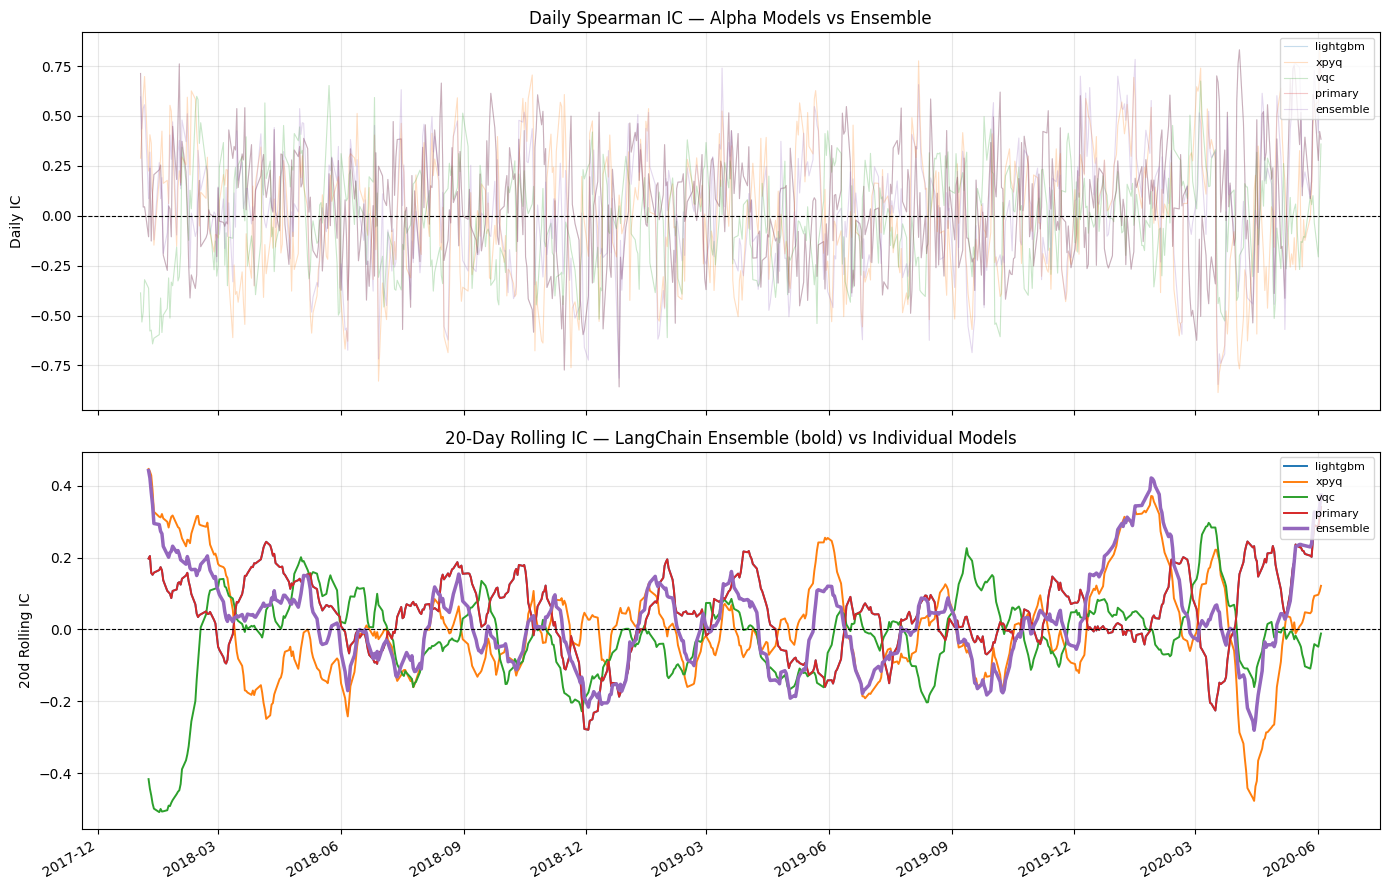

Chart saved → workspace/agent_ic_chart.png


In [59]:
y_test_full = master_test[TARGET].dropna()

alpha_mu_e = alpha_mu.copy()
alpha_mu_e['ensemble'] = (
    0.4 * alpha_mu_e.get('lightgbm', pd.Series(0, index=alpha_mu_e.index)).fillna(0) +
    0.3 * alpha_mu_e.get('xpyq',     pd.Series(0, index=alpha_mu_e.index)).fillna(0) +
    0.2 * alpha_mu_e.get('vqc',      pd.Series(0, index=alpha_mu_e.index)).fillna(0) +
    0.1 * alpha_mu_e.get('chronos',  pd.Series(0, index=alpha_mu_e.index)).fillna(0)
)

PLOT_MODELS = [c for c in ['lightgbm', 'xpyq', 'vqc', 'primary', 'ensemble']
               if c in alpha_mu_e.columns]
daily_ic_records = []

for d in TEST_DATES:
    if d not in y_test_full.index.get_level_values('timestamp'):
        continue
    actual_d = y_test_full.xs(d, level='timestamp')
    if len(actual_d) < 5:
        continue
    row = {'date': d}
    for m in PLOT_MODELS:
        try:
            pred_d = alpha_mu_e.xs(d, level='timestamp')[m]
            row[m] = spearman_ic(pred_d, actual_d)
        except Exception:
            pass
    daily_ic_records.append(row)

ic_daily   = pd.DataFrame(daily_ic_records).set_index('date')
ic_rolling = ic_daily.rolling(20, min_periods=5).mean()

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

for m in PLOT_MODELS:
    if m in ic_daily.columns:
        axes[0].plot(ic_daily.index, ic_daily[m], alpha=0.25, linewidth=0.8)
axes[0].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[0].set_ylabel('Daily IC')
axes[0].set_title('Daily Spearman IC — Alpha Models vs Ensemble')
axes[0].legend(PLOT_MODELS, fontsize=8, loc='upper right')
axes[0].grid(alpha=0.3)

colors = plt.cm.tab10.colors
for i, m in enumerate(PLOT_MODELS):
    if m in ic_rolling.columns:
        axes[1].plot(ic_rolling.index, ic_rolling[m], label=m,
                     linewidth=2.5 if m == 'ensemble' else 1.4,
                     color=colors[i % len(colors)])
axes[1].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[1].set_ylabel('20d Rolling IC')
axes[1].set_title('20-Day Rolling IC — LangChain Ensemble (bold) vs Individual Models')
axes[1].legend(fontsize=8, loc='upper right')
axes[1].grid(alpha=0.3)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
fig.autofmt_xdate()

plt.tight_layout()
plt.savefig(os.path.join(WORKSPACE, 'agent_ic_chart.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved → workspace/agent_ic_chart.png')

## 12. Stage 2.1 Readiness Summary

In [60]:
print('=' * 68)
print(' STAGE 2.1 — LANGCHAIN AGENTIC FORECASTER — READINESS SUMMARY')
print('=' * 68)

# Ensemble IC over full test period
ensemble_ic = spearman_ic(
    alpha_mu_e['ensemble'].reindex(y_test_full.index),
    y_test_full
)
ensemble_sh = long_short_sharpe(
    alpha_mu_e['ensemble'].reindex(y_test_full.index),
    y_test_full
)

print(f'\nEnsemble signal (full test period):')
print(f'  IC     : {ensemble_ic:+.4f}')
print(f'  Sharpe : {ensemble_sh:+.3f}')

print(f'\nAgent architecture:')
print(f'  QuantAnalyst     — signal quality + feature inspection')
print(f'  RiskScout        — regime detection + model decay monitoring')
print(f'  EnsembleOrchestrator — adaptive-weighted ensemble → trade brief')

print(f'\nOutputs saved:')
print(f'  {DATA_DIR}/agent_signals.parquet  ({len(signals_df):,} rows)')
print(f'  {WORKSPACE}/agent_ic_chart.png')

print(f'\nReady for Stage 3 (inference / live signal generation).')
print('=' * 68)

 STAGE 2.1 — LANGCHAIN AGENTIC FORECASTER — READINESS SUMMARY

Ensemble signal (full test period):
  IC     : +0.0375
  Sharpe : +0.534

Agent architecture:
  QuantAnalyst     — signal quality + feature inspection
  RiskScout        — regime detection + model decay monitoring
  EnsembleOrchestrator — adaptive-weighted ensemble → trade brief

Outputs saved:
  /Applications/Projects/Hackathons/quantum_ai/workspace/data/agent_signals.parquet  (620 rows)
  /Applications/Projects/Hackathons/quantum_ai/workspace/agent_ic_chart.png

Ready for Stage 3 (inference / live signal generation).
